# Synapse SQL Sessions: Introduction to Data Analysis with BigQuery

**Platform:** Google BigQuery  
**Focus:** Using SQL to understand and analyze data-not database administration.


## 1. Start with a real-world problem

Imagine that you work for an online shopping company such as Flipkart. Your team wants to build an ML model to:

- Recommend similar products to customers.
- Understand which products sell most.
- Identify products that suppliers may need to restock.
- Discover purchasing patterns.


**What does we need before create ML model?**


The data might include customers, orders, products, prices, dates, and quantities. If these details are scattered or inconsistent, analyzing them becomes difficult.

## 2. Why do we need structured data?

Consider this sentence:

> Krishna bought an iQOO phone on 15 October 2022 for ₹30,000. His customer ID is 142421.

A person can understand this sentence, but analyzing thousands or millions of similar sentences is harder. We need a consistent structure.

### The same information in a table

| customer_id | customer_name | order_date | product | price |
|---:|---|---|---|---:|
| 142421 | Krishna | 2022-10-15 | iQOO phone | 30000 |

A table gives each value a clear meaning. This makes it easier to filter records, calculate totals, compare products, and prepare data for analysis or ML.

**Ask students:** How would you find all orders made by customer `142421` if the company had one million orders?

## 3. Core terms: data, database, and DBMS

### Data
Raw facts or observations—for example, a customer ID, order date, product name, or price.

### Database
An organized collection of data.

### DBMS (Database Management System)
Software used to create, store, retrieve, and manage data in databases. Examples include MySQL and PostgreSQL.

### RDBMS (Relational Database Management System)
A type of DBMS that organizes data into related tables. Tables can be connected using keys, such as a customer ID or product ID.


## 5. RDBMS vs. BigQuery

Traditional relational database systems such as MySQL and PostgreSQL are commonly used for applications that need to store and update operational records.

**Google BigQuery** is a fully managed, serverless cloud data warehouse designed primarily for analytics at scale. It supports SQL and works with data arranged in tables.

| Topic | Traditional RDBMS | BigQuery |
|---|---|---|
| Common purpose | Application transactions and operational data | Large-scale data analysis |
| Typical workload | Frequent record-level reads and writes | Analytical queries over large datasets |
| SQL | Yes | Yes, using GoogleSQL |
| Infrastructure | Depends on how it is deployed | Serverless, managed service |


**Remember:** Both use SQL, but their main workloads and design priorities differ. BigQuery can support data ingestion and updates too; it is simply optimized for analytical workloads.

## 6. BigQuery structure: project → dataset → table

In BigQuery, data is organized using this hierarchy:

1. **Project:** A container for Google Cloud resources.
2. **Dataset:** A container for related tables and views.
3. **Table:** Rows and columns containing the data.


### Query 1: Display all columns and rows

```sql
SELECT *
FROM `dataset.tablename`
LIMIT 100;
```

#### Q. Which of the following companies uses data extensively?
- A. Amazon
- B. Swiggy
- C. Netflix
- D. All of the above

#### **SQL** stands for: Structured Query Language

#### **SQL is case-insensitive.**

### For see the Output:

```sql
select column_name1,column_name2 / * 
from dataset.tablename 
```

-- Show the names of all the customers

-- Show customer cities

-- Finance wants only payment methods?

-- HR wants employee names

Alter table `e1.employees`
rename column string_field_0 to EmployeeID

delete from `e1.employees`
where EmployeeID = "EmployeeID"

# Distinct

-- Show all different city of customers belong

-- Different payment methods

## Correct the supplier table

-- How many distinct amounts do in payment table?

-- on which dates there has been atleast 1 customer who signed up

-- what are the unique combinations of payment methods and payment status

# Where

-- Give me information of the customer with id C014

**-- Find customers who have spent more than ₹1,00,000. --> this will need join concept**

-- The Customer Support team wants a list of all customers with their city.

-- Show all product categories available.

## OPERATERS

-- Display Female Customers

-- Display Customers Older Than 30

-- Display Products Costing at most ₹50,000

-- Display Orders That Are Not Delivered

## COUNT

-- Count Customers from Mumbai

-- The HR Manager wants number of employees working in the Operations
department.

-- The Inventory team wants to see products having stock less than 30 units

-- Find all customers who signed up after 2023-01-0

-- Count how many different product categories exist in the products table.

### --calculates the number of rows

In [ ]:
select count(*)
from `e1.customers`

### Sum()

Total Sales Value
What is the total value represented by all order-item records?

In [ ]:
select sum(Total)
from `e1.order_items`

Total quantity sold where order items have a quantity greater than 1:

In [ ]:
select sum(quantity)
from `e1.order_items`
where quantity > 1

### AVG

what is the average selling price of the products?

In [ ]:
select avg(SellingPrice)
from `e1.products`

In [ ]:
select avg(SellingPrice) as avg_selling_price
from `e1.products`

### ALL Opration

The Finance team wants a summary of all payment transactions

In [ ]:
select
count(*) as no_of_payments,
sum(amount) as total_payment_amt,
avg(amount) as avg_payment,
min(amount) as min_payment,
max(amount) as max_payment
from `e1.payments`

### Group by

give me the count of the number of products within each category

In [ ]:
select
CategoryID,
count(*) as prd_cnt
from `e1.products`
group by CategoryID

How many units of each product have been sold?

In [ ]:
select
ProductID,
sum(Quantity) as total_qty
from `e1.order_items`
group by ProductID

Product Sales Summary -> for every product, what is the statstics summary

In [ ]:
select
ProductID,
count(*) as total_orders,
sum(total) as total_sales,
max(total) as max_sale,
min(total) as min_sale,
round(avg(total), 2) as avg_sale
from `e1.order_items`
group by ProductID

### Order by --> ASC(default) OR DESC

WORK FOR NUMBER AND ALPHABET and dates 

sort products from most expensive selling price to least

In [ ]:
select
ProductID,
SellingPrice
from `e1.products`
order by SellingPrice desc

In [ ]:
select
ProductID,
SellingPrice
from `e1.products`
order by SellingPrice desc,ProductID asc

### HAVING

1. Take products

        ↓
2. Keep MRP > 1000

        ↓
3. Create supplier groups

        ↓
4. Count products

        ↓
5. Keep suppliers with > 2 products

        ↓
6. Sort highest count first

        ↓
7. Show top 5

In [ ]:
select
SupplierID,
count(*) as prd_cnt
from `e1.products`
where MRP > 1000
group by SupplierID
having prd_cnt > 2
order by prd_cnt desc
limit 5

Products with Sales Above ₹50,000

In [ ]:
select
ProductID,
sum(total) as total_sales
from `e1.order_items`
group by ProductID
having total_sales > 50000

### filter out those products whose mrp is min among the top 5 distinct highest mrps

In [ ]:
select min(select distinct(MRP)
from `e1.products`
order by MRP desc
limit 5)
from `e1.products

## JOIN (IMPORTANT)

"Show me the product name and the category name."

products -- Product Name

linkage: categoryID

Category -- category Name

In [ ]:
syntax:

select
from table1
join table2
on table1.key = table2.key

alter table `e1.categories`
rename column string_field_0 to CategoryID

In [ ]:
select
p.ProductID,
p.ProductName,
c.CategoryID,
c.CategoryName
from `e1.categories` as c
inner join `e1.products` as p
on c.CategoryID = p.CategoryID

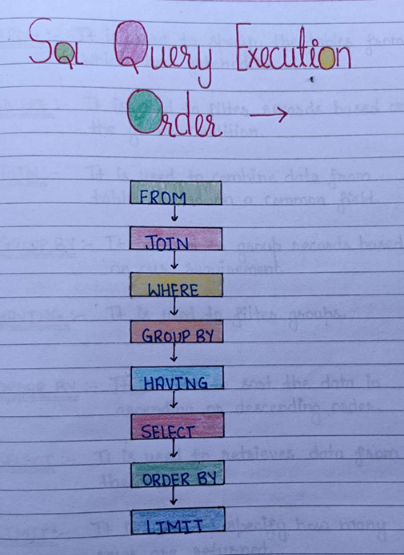

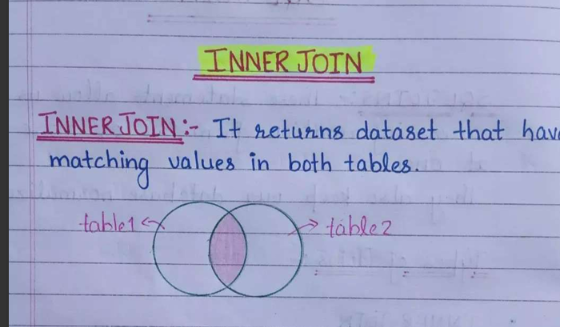

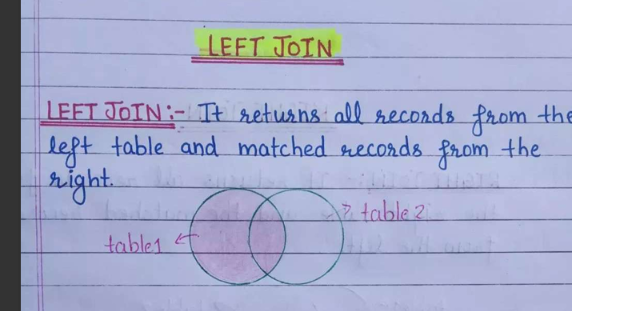

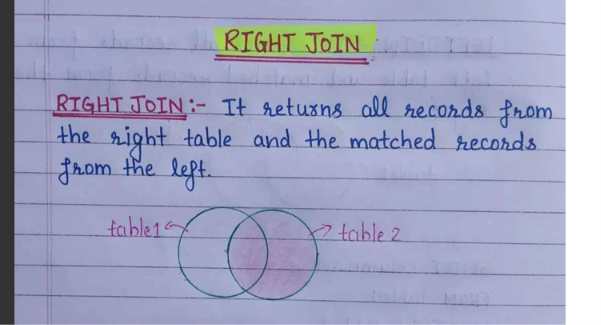

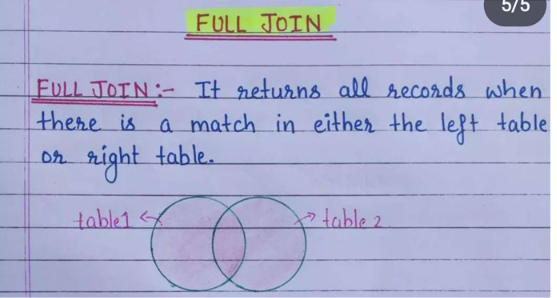